<a href="https://colab.research.google.com/github/M-Roshan0708/-Cars-Dataset-EDA-Project/blob/main/M_Roshan_EDA_MinorProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy matplotlib seaborn

In [ ]:
# Import Library
import pandas as pd # data manipulation/analysis
import numpy as np #mathematical operations
import matplotlib.pyplot as plt # visualization
import seaborn as sns # visualization

In [ ]:
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)



Saving cars_dataset.csv to cars_dataset.csv


In [ ]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Make
0,A1,2017,12500,Manual,15735,Petrol,150.0,55.4,1.4,audi
1,A6,2016,16500,Automatic,36203,Diesel,20.0,64.2,2.0,audi
2,A1,2016,11000,Manual,29946,Petrol,30.0,55.4,1.4,audi
3,A4,2017,16800,Automatic,25952,Diesel,145.0,67.3,2.0,audi
4,A3,2019,17300,Manual,1998,Petrol,145.0,49.6,1.0,audi


In [ ]:
df.tail()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Make
72430,I30,2016,8680,Manual,25906,Diesel,0.0,78.4,1.6,Hyundai
72431,I40,2015,7830,Manual,59508,Diesel,30.0,65.7,1.7,Hyundai
72432,I10,2017,6830,Manual,13810,Petrol,20.0,60.1,1.0,Hyundai
72433,Tucson,2018,13994,Manual,23313,Petrol,145.0,44.8,1.6,Hyundai
72434,Tucson,2016,15999,Automatic,11472,Diesel,125.0,57.6,1.7,Hyundai


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72435 entries, 0 to 72434
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         72435 non-null  object 
 1   year          72435 non-null  int64  
 2   price         72435 non-null  int64  
 3   transmission  72435 non-null  object 
 4   mileage       72435 non-null  int64  
 5   fuelType      72435 non-null  object 
 6   tax           72435 non-null  float64
 7   mpg           72435 non-null  float64
 8   engineSize    72435 non-null  float64
 9   Make          72435 non-null  object 
dtypes: float64(3), int64(3), object(4)
memory usage: 5.5+ MB


In [ ]:
df.duplicated().sum()

np.int64(842)

df.drop_duplicates().sum()

In [ ]:
df.drop_duplicates().sum()

,0
model,0
year,0
price,0
transmission,0
mileage,0
fuelType,0
tax,0
mpg,0
engineSize,0
Make,0


In [ ]:

# Missing value treatment

#if the column is numerical/ categorical

#Numerical - Median, categorical - Mode




In [ ]:
df = df.fillna(df.mode().iloc[0])

# numericals missing value treatment
num =  df.select_dtypes(include ='number').columns
df[num] = df[num].fillna(df[num].median())

In [ ]:
df.isnull().sum()

,0
model,0
year,0
price,0
transmission,0
mileage,0
fuelType,0
tax,0
mpg,0
engineSize,0
Make,0


In [ ]:
# Numerical values
df.select_dtypes(include = ['int64','float64']).columns

Index(['year', 'price', 'mileage', 'tax', 'mpg', 'engineSize'], dtype='object')

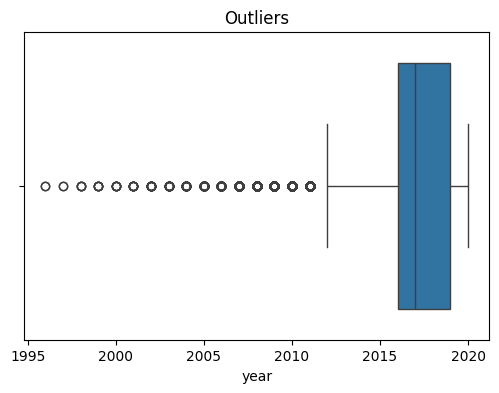

In [ ]:
# Outlier check
plt.figure(figsize= (6,4))
sns.boxplot(x = df['year'])
plt.title("Outliers")
plt.show()

In [ ]:
Q1 = df['year'].quantile(0.25)
Q3 = df['year'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [ ]:
df['year'] = df['year'].clip(lower_bound, upper_bound)

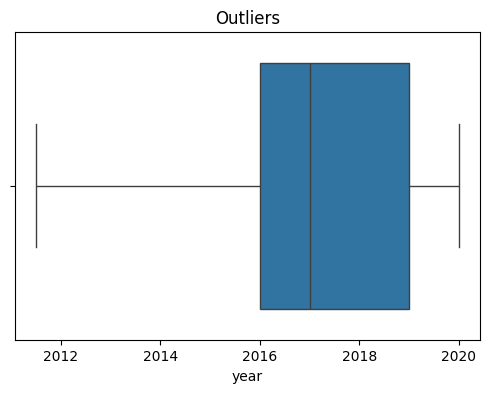

In [ ]:
# Outlier check
plt.figure(figsize= (6,4))
sns.boxplot(x = df['year'])
plt.title("Outliers")
plt.show()

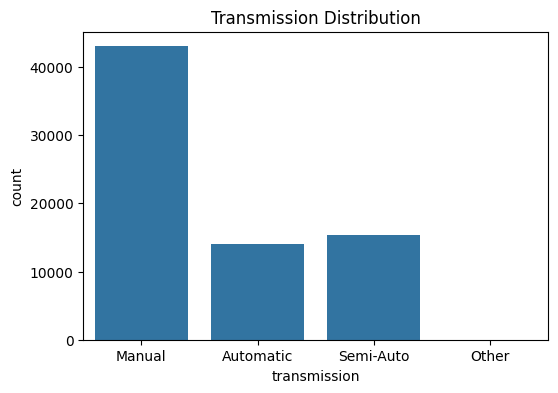

In [ ]:
# Univariate analysis
plt.figure(figsize=(6, 4))
sns.countplot(x = df['transmission'])
plt.title("Transmission Distribution")
plt.show()

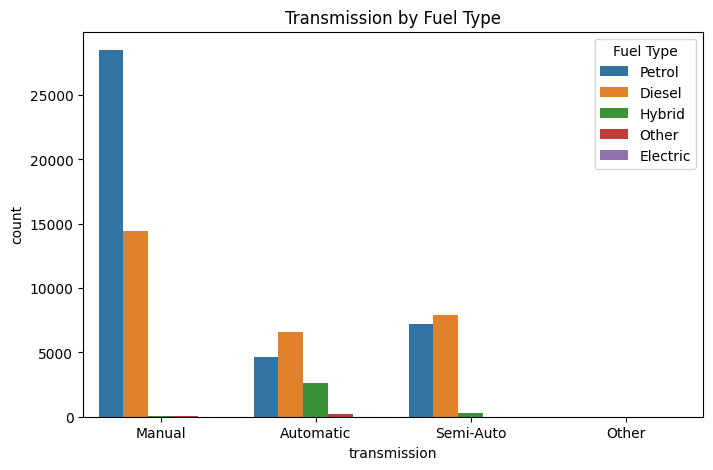

In [ ]:
# Bivariate analysis
plt.figure(figsize=(8, 5))
sns.countplot(x = df['transmission'], hue = df['fuelType'])
plt.title("Transmission by Fuel Type")
plt.legend(title='Fuel Type')
plt.show()

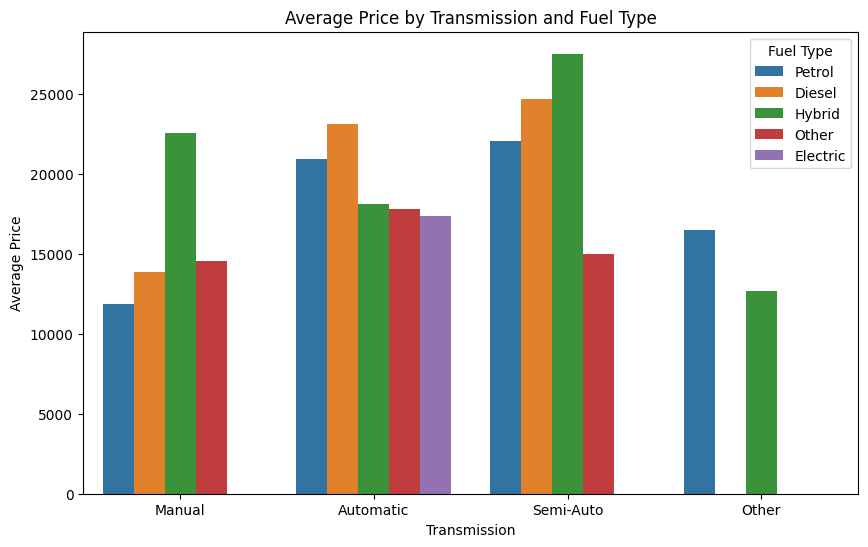

In [ ]:
# Multivariate analysis: Car Price by Transmission and Fuel Type
plt.figure(figsize=(10, 6))
sns.barplot(x='transmission', y='price', hue='fuelType', data=df, errorbar=None)
plt.title("Average Price by Transmission and Fuel Type")
plt.ylabel("Average Price")
plt.xlabel("Transmission")
plt.legend(title='Fuel Type')
plt.show()

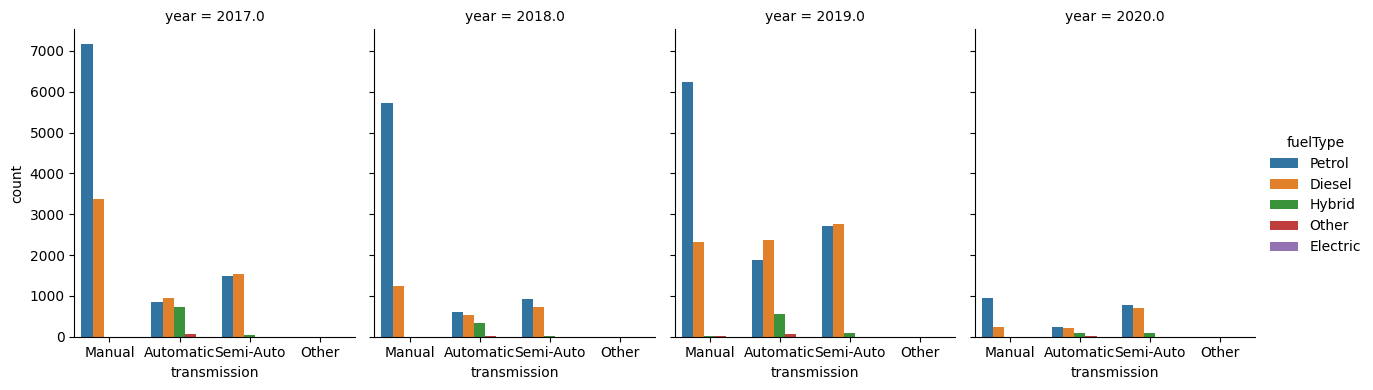

In [ ]:
# Multidimensional analysis across years
sns.catplot(x='transmission', hue='fuelType', col='year', data=df[df['year'] >= 2017], kind='count', height=4, aspect=0.8)
plt.show()

In [ ]:
# converting objective data to numerical
df1= df.select_dtypes(include = 'object').columns
df1

Index(['model', 'transmission', 'fuelType', 'Make'], dtype='object')

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in df1:
  df[col] = le.fit_transform(df[col])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72435 entries, 0 to 72434
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         72435 non-null  int64  
 1   year          72435 non-null  float64
 2   price         72435 non-null  int64  
 3   transmission  72435 non-null  int64  
 4   mileage       72435 non-null  int64  
 5   fuelType      72435 non-null  int64  
 6   tax           72435 non-null  float64
 7   mpg           72435 non-null  float64
 8   engineSize    72435 non-null  float64
 9   Make          72435 non-null  int64  
dtypes: float64(4), int64(6)
memory usage: 5.5 MB
